# BigMart sales: what drives them, and how well can we predict them?

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/benisalla/BigMart-Data-Analysis-and-Prediction/blob/main/notebooks/bigmart_sales_analysis.ipynb)

BigMart recorded the 2013 sales of **1,559 products in 10 stores**. The goal is to
predict `Item_Outlet_Sales` for each product/store pair and, more usefully, to find
**which product and store properties drive sales**, so the business knows where to act.

This notebook is the full analysis, end to end. All the code lives in the `bigmart`
package of the repository (https://github.com/benisalla/BigMart-Data-Analysis-and-Prediction); the notebook calls it, so you can read the story
here and reuse every step from Python.

1. The data and its problems
2. Hypotheses: what should drive sales?
3. Exploratory analysis: what actually drives sales
4. Models, compared with 5-fold cross-validation
5. Conclusions and recommendations

In [1]:
# Use the local package when run from the repo; install it from GitHub on Colab / Kaggle.
try:
    import bigmart
except ImportError:
    %pip install -q git+https://github.com/benisalla/BigMart-Data-Analysis-and-Prediction
    import bigmart

import os
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

plt.ioff()  # figures are shown once, by plots.show

from bigmart import plots
from bigmart.data import load_test, load_train, split_xy

# The data ships in the repo; on Colab / Kaggle the files are fetched from GitHub.
RAW = "https://raw.githubusercontent.com/benisalla/BigMart-Data-Analysis-and-Prediction/main/data/raw"
local = Path(bigmart.__file__).resolve().parents[2] / "data" / "raw" / "Train.csv"
train_path, test_path = (None, None) if local.exists() else (f"{RAW}/Train.csv", f"{RAW}/Test.csv")

raw = load_train(train_path)
test = load_test(test_path)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 110)
print(f"train {raw.shape}, test {test.shape}")
raw.head()

train (8523, 12), test (5681, 11)


,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales
0,FDA15,9.30,Low Fat,0.016047,Dairy,249.8092,OUT049,1999,Medium,Tier 1,Supermarket Type1,3735.1380
1,DRC01,5.92,Regular,0.019278,Soft Drinks,48.2692,OUT018,2009,Medium,Tier 3,Supermarket Type2,443.4228
2,FDN15,17.50,Low Fat,0.016760,Meat,141.6180,OUT049,1999,Medium,Tier 1,Supermarket Type1,2097.2700
3,FDX07,19.20,Regular,0.000000,Fruits and Vegetables,182.0950,OUT010,1998,NaN,Tier 3,Grocery Store,732.3800
4,NCD19,8.93,Low Fat,0.000000,Household,53.8614,OUT013,1987,High,Tier 3,Supermarket Type1,994.7052


## 1. The data and its problems

Each row is one product in one store. Eleven features describe the product (identifier,
weight, fat content, visibility, type, list price `Item_MRP`) and the store (identifier,
opening year, size, location tier, type). The data has four quality problems:

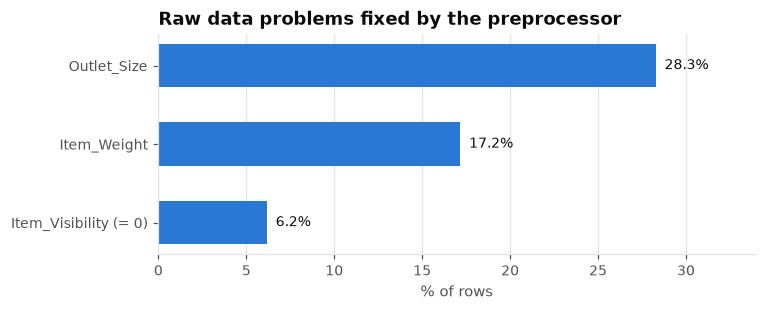

{'Low Fat': 5089, 'Regular': 2889, 'LF': 316, 'reg': 117, 'low fat': 112}
stores with no Outlet_Size: ['OUT010', 'OUT017', 'OUT045']


In [2]:
plots.show(plots.missing_values(raw))
print(raw["Item_Fat_Content"].value_counts().to_dict())
print("stores with no Outlet_Size:", sorted(raw.loc[raw.Outlet_Size.isna(), "Outlet_Identifier"].unique()))

| Problem | Fix (in `BigMartPreprocessor`) |
|---|---|
| `Item_Weight` missing in 17% of rows | the same product is sold in other stores with its weight: fill per `Item_Identifier` |
| `Outlet_Size` missing for 3 whole stores | most common size among stores of the same `Outlet_Type` |
| `Item_Visibility` = 0 in 526 rows (impossible for a product that sells) | the product's mean visibility |
| `Item_Fat_Content` has 5 spellings; household/health products have a "fat content" | map to Low Fat / Regular, and Non-Edible for non-consumables |

Three features are added: `Item_Category` (Food / Drinks / Non-Consumable, from the
identifier prefix), `Outlet_Age` and `Item_Visibility_Ratio`. Everything the preprocessor
learns (weights, visibilities, sizes) is learned in `fit`, on training rows only, so it
can sit inside a cross-validated pipeline without leaking validation data.

In [3]:
from bigmart.preprocessing import clean

tidy = clean(raw)
print("missing values after cleaning:", int(tidy.isna().sum().sum()))
tidy.head()

missing values after cleaning: 0


,Item_Fat_Content,Item_Type,Item_Category,Outlet_Identifier,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Weight,Item_Visibility,Item_Visibility_Ratio,Item_MRP,Outlet_Age,Item_Outlet_Sales
0,Low Fat,Dairy,Food,OUT049,Medium,Tier 1,Supermarket Type1,9.30,0.016047,0.922960,249.8092,14,3735.1380
1,Regular,Soft Drinks,Drinks,OUT018,Medium,Tier 3,Supermarket Type2,5.92,0.019278,1.003057,48.2692,4,443.4228
2,Low Fat,Meat,Food,OUT049,Medium,Tier 1,Supermarket Type1,17.50,0.016760,0.831990,141.6180,14,2097.2700
3,Regular,Fruits and Vegetables,Food,OUT010,Small,Tier 3,Grocery Store,19.20,0.022911,1.000000,182.0950,15,732.3800
4,Non-Edible,Household,Non-Consumable,OUT013,High,Tier 3,Supermarket Type1,8.93,0.016164,1.000000,53.8614,26,994.7052


## 2. Hypotheses: what should drive sales?

Before looking at the data, the project listed what *should* matter: product price,
quality and health (fat content), shelf visibility, product category; store size,
location (city tier), format and age. Each one is tested below.

## 3. Exploratory analysis

### Sales are price x units

The target is skewed, but dividing it by the list price gives a "units sold" proxy that
is much better behaved, and that clearly separates the store types.

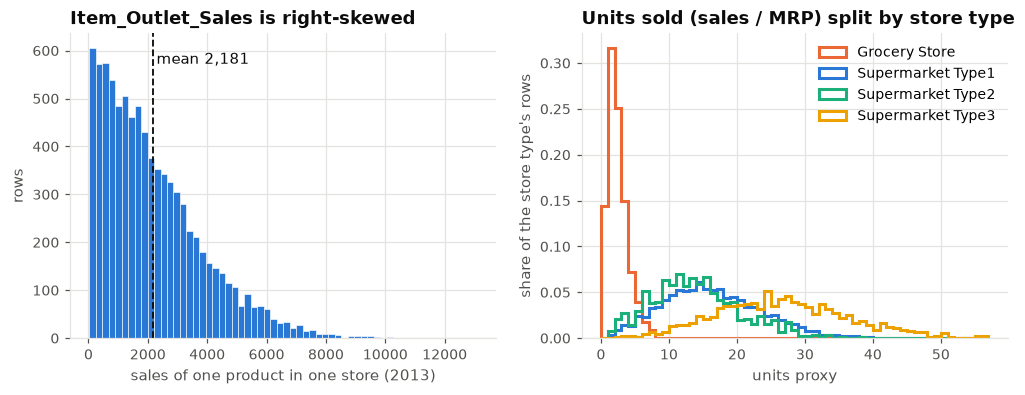

In [4]:
plots.show(plots.sales_distribution(tidy))

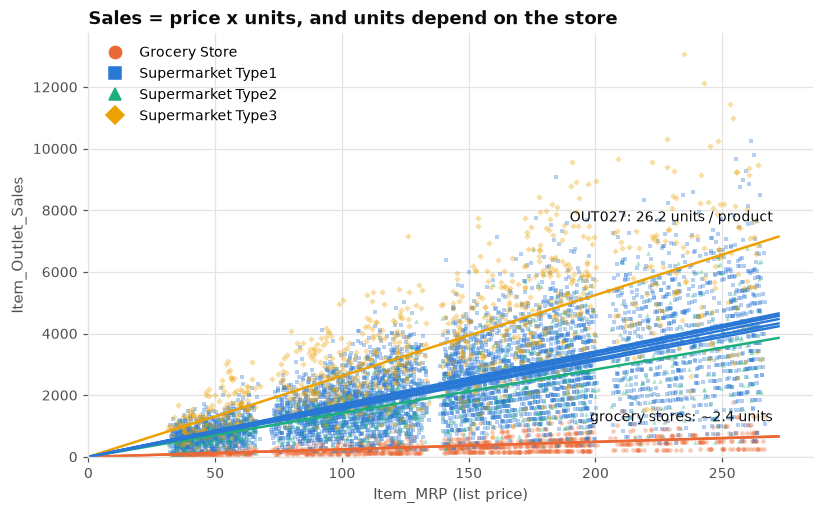

In [5]:
from bigmart.models import build_model

store_price = build_model("store_price").fit(*split_xy(raw))
plots.show(plots.price_vs_sales(tidy, store_price.multipliers_))

Each line is one store's least-squares fit of `sales = k * MRP`. Within a store, the
points fan out around a straight line through the origin: revenue grows with price
because **the number of units sold does not fall with price**. The slope `k` (units per
product) is set by the store: ~2.4 in the two grocery stores, 14-17 in supermarkets,
26 in the one Type 3 supermarket (OUT027).

The price axis also shows four price bands (gaps near 70, 135 and 200), a sign that
BigMart prices in tiers.

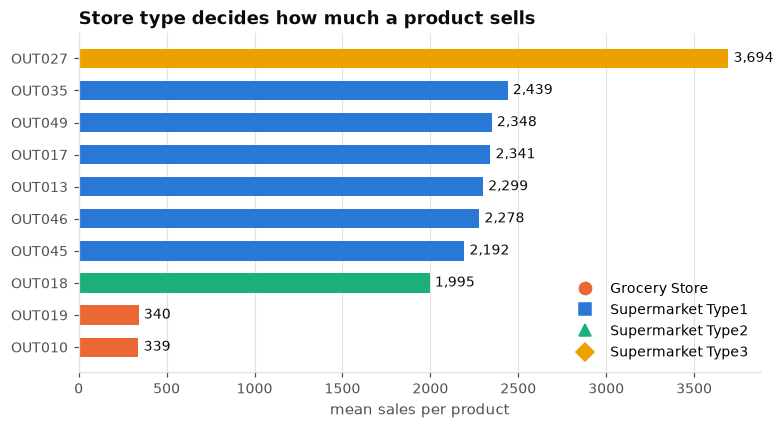

,type,size,tier,age,products,mean_sales,mean_units,revenue,revenue_share
Outlet_Identifier,,,,,,,,,
OUT027,Supermarket Type3,Medium,Tier 3,28,935,3694.039,26.609,3453926.051,0.186
OUT035,Supermarket Type1,Small,Tier 2,9,930,2438.842,16.974,2268122.935,0.122
OUT049,Supermarket Type1,Medium,Tier 1,14,930,2348.355,16.630,2183969.810,0.117
OUT017,Supermarket Type1,Small,Tier 2,6,926,2340.675,16.660,2167465.294,0.117
OUT013,Supermarket Type1,High,Tier 3,26,932,2298.995,16.001,2142663.578,0.115
OUT046,Supermarket Type1,Small,Tier 1,16,930,2277.844,16.191,2118395.168,0.114
OUT045,Supermarket Type1,Small,Tier 2,11,929,2192.385,15.582,2036725.477,0.110
OUT018,Supermarket Type2,Medium,Tier 3,4,928,1995.499,13.852,1851822.830,0.100
OUT019,Grocery Store,Small,Tier 1,28,528,340.330,2.445,179694.094,0.010


In [6]:
from bigmart.insights import store_summary, units_near_integer_share

plots.show(plots.sales_by_store(tidy))
store_summary(tidy).round(3)

In [7]:
near, expected = units_near_integer_share(raw)
print(f"sales / MRP is within 0.05 of a whole number in {near:.0%} of rows (uniform would give {expected:.0%})")

sales / MRP is within 0.05 of a whole number in 34% of rows (uniform would give 10%)


That last check supports the reading of `sales / MRP` as units: a third of the rows sit
close to a whole number of units, three times more than chance.

### Product attributes barely matter

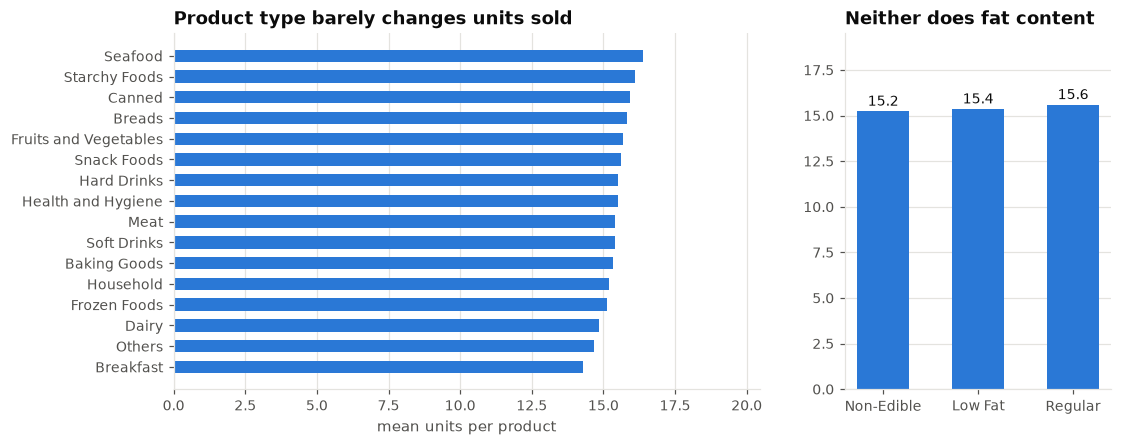

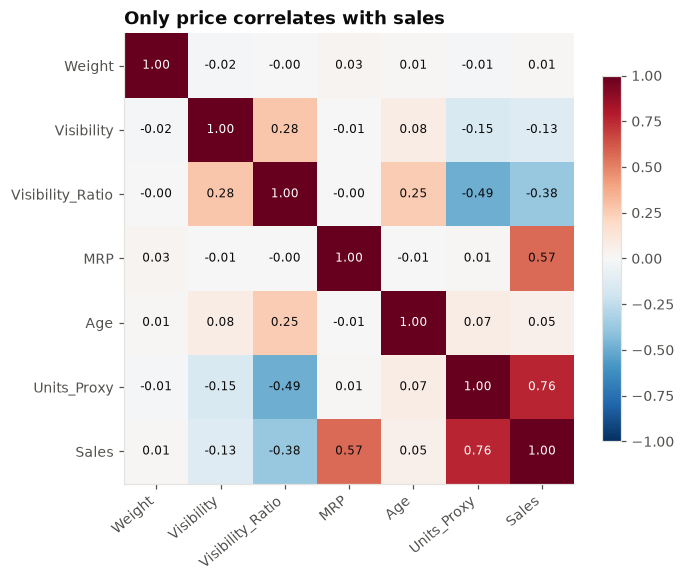

In [8]:
plots.show(plots.units_by_product(tidy))
plots.show(plots.correlation_heatmap(tidy))

### The hypotheses, tested

In [9]:
from bigmart.insights import check_hypotheses

check_hypotheses(tidy)

,hypothesis,evidence,verdict
0,Higher-priced products bring more revenue,"corr(MRP, sales) = 0.57; MRP alone explains 32% of the variance",Confirmed: the strongest driver
1,Price lowers the number of units sold,"corr(MRP, units) = 0.01",Rejected: units sold do not depend on price
2,Store format drives sales,"units per product: grocery 2.4, supermarkets 13.9-26.6; eta2 = 0.24",Confirmed: grocery stores sell ~7x fewer units
3,Bigger stores sell more,"High 2,299, Medium 2,682, Small 1,867; eta2 = 0.048",Weak: the size label adds little once store type is known
4,Location tier (city size) matters,"Tier 1 1,877, Tier 2 2,324, Tier 3 2,280; eta2 = 0.013",Weak: mostly reflects which store types sit in each tier
5,"Older, established stores sell more","corr(store age, sales) = 0.05; oldest store OUT027 (1985) is the best seller, OUT019 (1985) is among the w...",Rejected: age is not a driver on its own
6,More shelf visibility means more sales,"corr(visibility, sales) = -0.13","Rejected: slightly negative, not positive"
7,Healthy (low-fat) products sell more,units: Low Fat 15.4 vs Regular 15.6; ANOVA p = 0.29,Rejected: no difference
8,Some product categories sell much better,units per product range 14.3-16.4 across 16 types; eta2 = 0.001,Rejected: category barely matters


## 4. Models

Every product and every store of `Test.csv` also appears in `Train.csv`, so shuffled
5-fold cross-validation matches the real task. RMSE (the competition metric) is the main
score. Every model is a full pipeline, refitted on each fold:

    raw rows -> BigMartPreprocessor -> encoding -> regressor

The candidates: a mean baseline, linear and ridge regression (one-hot features), random
forest, gradient boosting and XGBoost (ordinal features), and **Store x price**, the
10-parameter model the EDA points to (`sales = k[store] * Item_MRP`).

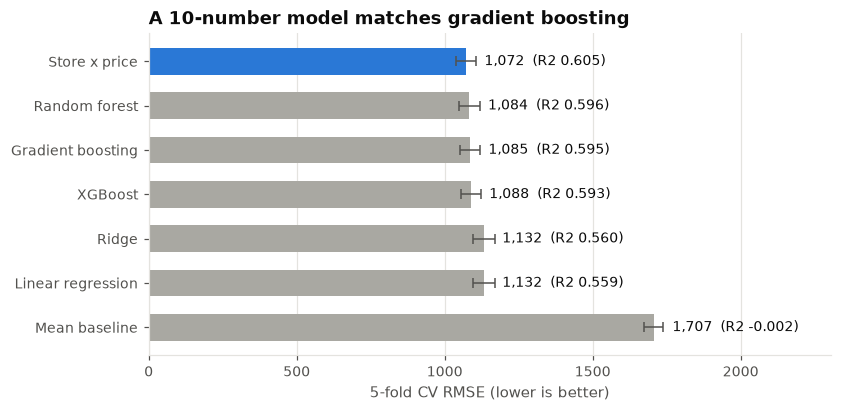

,label,rmse,rmse_std,mae,r2
0,Store x price,1071.618,33.415,750.268,0.605
1,Random forest,1083.666,35.720,757.145,0.596
2,Gradient boosting,1084.932,33.504,758.783,0.595
3,XGBoost,1087.804,34.232,760.670,0.593
4,Ridge,1131.766,37.637,839.456,0.560
5,Linear regression,1131.798,37.653,839.475,0.559
6,Mean baseline,1706.712,32.204,1346.940,-0.002


In [10]:
from bigmart.evaluate import compare_models

X, y = split_xy(raw)
results = compare_models(X, y)
plots.show(plots.model_comparison(results))
results[["label", "rmse", "rmse_std", "mae", "r2"]].round(3)

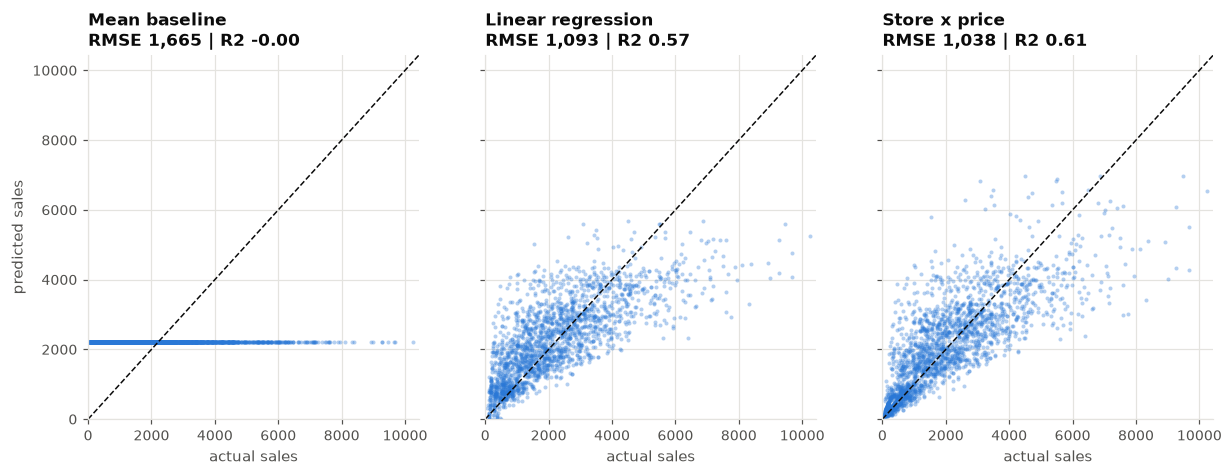

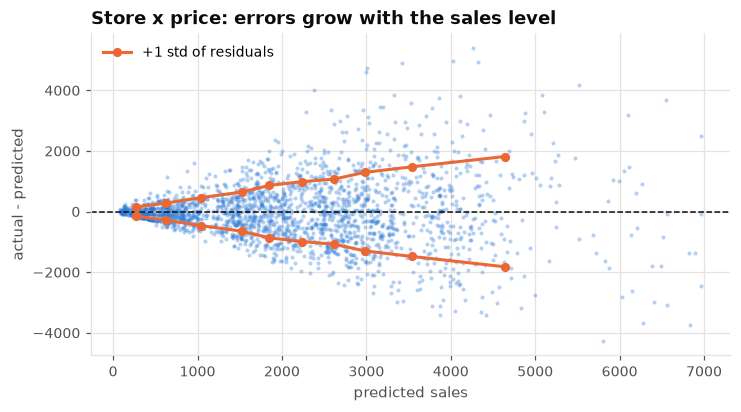

In [11]:
from bigmart.evaluate import holdout_predictions
from bigmart.models import LABELS

preds = holdout_predictions(X, y, ["mean_baseline", "linear_regression", "store_price"])
plots.show(plots.predicted_vs_actual(preds, ["mean_baseline", "linear_regression", "store_price"], LABELS))
plots.show(plots.residuals(preds, "store_price", LABELS["store_price"]))

The error grows with the sales level: a product's units vary a lot around its store's
average, and nothing in the data explains that variation. This is why every model,
however flexible, stops near R2 = 0.60.

### What the flexible models learn

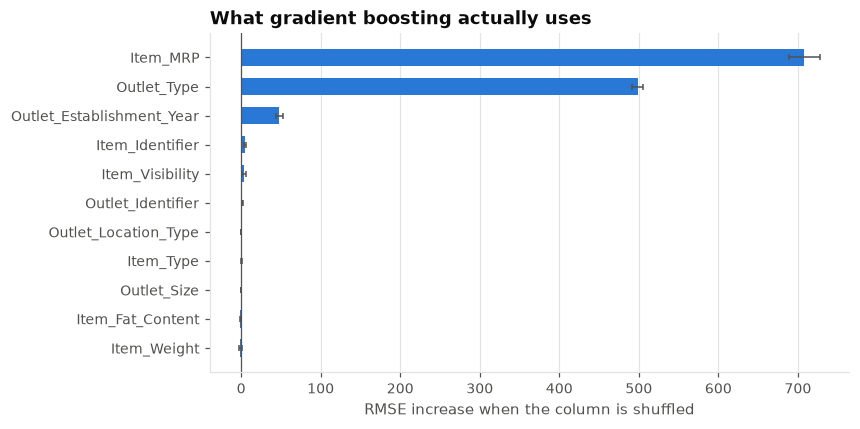

,feature,rmse_increase,std
0,Item_MRP,708.3,19.7
1,Outlet_Type,498.4,6.8
2,Outlet_Establishment_Year,47.8,4.3
3,Item_Identifier,4.5,1.5
4,Item_Visibility,3.6,2.4
5,Outlet_Identifier,1.4,0.8
6,Outlet_Location_Type,0.3,0.1
7,Item_Type,0.2,0.4
8,Outlet_Size,-0.1,0.2
9,Item_Fat_Content,-0.9,0.5


In [12]:
from bigmart.evaluate import feature_importance, holdout_split

X_tr, X_va, y_tr, y_va = holdout_split(X, y)
gbm = build_model("gradient_boosting").fit(X_tr, y_tr)
importance = feature_importance(gbm, X_va, y_va)
plots.show(plots.feature_importance(importance, "What gradient boosting actually uses"))
importance.round(1)

Gradient boosting, given all eleven columns, ends up using two: price and store type
(the opening year acts as a store identifier). It rediscovers the Store x price model,
with more parameters and slightly more variance.

### Submission for Test.csv

In [13]:
submission = test[["Item_Identifier", "Outlet_Identifier"]].assign(
    Item_Outlet_Sales=store_price.predict(test).clip(min=0)
)
submission.head()

,Item_Identifier,Outlet_Identifier,Item_Outlet_Sales
0,FDW58,OUT049,1812.871076
1,FDW14,OUT017,1470.043958
2,NCN55,OUT010,590.379881
3,FDQ58,OUT017,2610.024245
4,FDY38,OUT027,6148.033855


## 5. Conclusions

- **Sales = list price x units sold.** Price alone explains 32% of the variance; units do
  not fall as price rises.
- **The store decides the units.** A product sells ~2.4 units in a grocery store, ~16 in a
  Type 1 supermarket and ~26 in the Type 3 supermarket (OUT027), which brings 19% of
  revenue alone. Store format explains far more than size, city tier or age.
- **Product attributes do not move units**: fat content, category, weight and shelf
  visibility have no meaningful effect.
- **A 10-number model is the best predictor**: Store x price reaches CV RMSE 1,072
  (R2 0.605), ahead of random forest, gradient boosting and XGBoost (1,084-1,088), with
  no tuning, in milliseconds, and fully explainable.
- **The ceiling is the data, not the model.** The remaining 40% of the variance is
  product-in-store variation that no column describes. Promotions, shelf position,
  local demand or stock-outs would be the data to collect next.

**For the business:** growth comes from the store side (converting grocery stores and
Type 1 supermarkets toward the Type 3 format, which sells 1.6x more units per product),
not from product attributes like fat content or packaging visibility.